<div style="color:#3c4d5a; background-color:#fff; border-top:7px solid #42A5F5; border-bottom:7px solid #42A5F5; padding:16px 8px; text-align:center; text-transform:uppercase;">
<h2 style="color:inherit; border:0; margin:8px 0;">UNIVERSIDAD POLITÉCNICA SALESIANA</h2>
<h3 style="color:inherit; margin:8px 0;">Carrera de Computación · Aprendizaje Automático</h3>
<h1 style="color:inherit; margin:14px 0;">Práctica 2: Predicción de demanda con SVM</h1>
</div>

<p><b>Desarrollado por:</b> Daniel Guanga , Alex Guamán y Cinthya Ramón<br>
<b>Docente:</b> Ing. Remigio Hurtado · <b>Fecha:</b> noviembre 2026</p>


**Dataset:** el mismo de la Práctica 1 (escenario sintético de La Favorita): 10 productos, 365 días (01/10/2025 – 30/09/2026), 3.650 ventas.
- `sales_history.csv`: producto, fecha, `cantidad_vendida` (demanda) y `stock_en_momento` (stock al inicio del día).
- `inventory.csv`: categoría y unidad de cada producto.

**Objetivo:** predecir la demanda diaria con una **SVR** (SVM para regresión) y compararla con la LSTM de la Práctica 1 (RMSE 4,40 en septiembre de 2026).

<div id="contenido" style="color:#37475a; background-color:#fff; border-bottom:7px solid orange; width:100%; margin:24px 0 15px; padding-bottom:2px;"><h2 style="color:inherit;">Contenido</h2></div>

- [Parte 1: Datos y SVR](#parte1)
  - [1.1 Variables de entrada](#variables-entrada)
  - [1.2 División por fechas](#division-fechas)
  - [1.3 Comparación de kernels](#comparacion-kernels)
  - [1.4 Efecto de C](#regularizacion-c)
  - [1.5 Efecto de épsilon](#efecto-epsilon)
  - [1.6 Evaluación en prueba](#evaluacion-prueba)
- [Parte 2: Optimización con MLflow](#parte2)
  - [2.1 Preparación y validación temporal](#preparacion-parte2)
  - [2.2 Experimentos en MLflow](#experimentos-mlflow)
  - [2.3 GridSearch frente a RandomSearch](#grid-frente-random)
  - [2.4 Registro del mejor modelo](#registro-modelo)
  - [2.5 Resultados y entrega para la Parte 3](#resultados-parte2)
- [Conclusiones de la Parte 1](#conclusiones-parte1)
- [Referencias](#referencias)


<div id="parte1" style="color:#37475a; background-color:#fff; border-bottom:7px solid orange; width:100%; margin-top:24px; margin-bottom:15px; padding-bottom:2px;"><h2 style="color:inherit;">Parte 1: Datos y SVR</h2></div>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import holidays
from pathlib import Path
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, mean_absolute_error

FIG = Path("figuras"); FIG.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

ventas = pd.read_csv("data/sales_history.csv", dtype={"product_id": str}, parse_dates=["fecha_venta"])
inventario = pd.read_csv("data/inventory.csv", dtype={"product_id": str})
ventas = ventas.sort_values(["product_id", "fecha_venta"]).reset_index(drop=True)
ventas["stock_cierre"] = ventas["stock_en_momento"] - ventas["cantidad_vendida"]
print(ventas.shape)
ventas.head()

(3650, 6)


,product_id,nombre,fecha_venta,cantidad_vendida,stock_en_momento,stock_cierre
0,103665,Pan de Molde Blanco,2025-10-01,34.0,140.0,106.0
1,103665,Pan de Molde Blanco,2025-10-02,32.0,106.0,74.0
2,103665,Pan de Molde Blanco,2025-10-03,39.0,74.0,35.0
3,103665,Pan de Molde Blanco,2025-10-04,47.0,140.0,93.0
4,103665,Pan de Molde Blanco,2025-10-05,40.0,93.0,53.0


<div id="variables-entrada" style="color:#37475a; background-color:#fff; border-bottom:3px solid #42A5F5; width:100%; margin-top:24px; margin-bottom:15px; padding-bottom:2px;"><h3 style="color:inherit;">1.1 Variables de entrada</h3></div>

La SVM no recuerda el orden del tiempo como la LSTM, por eso cada fila debe traer su propio contexto: la **fecha como timestamp**, el calendario y los rezagos de la venta y del stock. Los rezagos solo usan días anteriores, así no hay fuga.

In [2]:
FERIADOS = pd.DatetimeIndex(list(holidays.EC(years=[2025, 2026]).keys()))
VISPERAS = FERIADOS - pd.Timedelta(days=1)

def crear_variables(df):
    X = pd.DataFrame(index=df.index)
    f = df["fecha_venta"]
    X["timestamp"] = f.astype("datetime64[s]").astype("int64")
    X["dia_semana"] = f.dt.dayofweek
    X["mes"] = f.dt.month
    X["fin_de_semana"] = (f.dt.dayofweek >= 5).astype(int)
    X["es_feriado"] = f.isin(FERIADOS).astype(int)
    X["vispera_feriado"] = f.isin(VISPERAS).astype(int)
    X["dia_pago"] = (f.dt.day.between(14, 16) | (f.dt.day >= f.dt.days_in_month - 2)).astype(int)
    X["navidad"] = ((f.dt.month == 12) & (f.dt.day >= 15)).astype(int)
    g = df.groupby("product_id")
    X["venta_ayer"] = g["cantidad_vendida"].shift(1)
    X["venta_hace_7"] = g["cantidad_vendida"].shift(7)
    X["media_7"] = g["cantidad_vendida"].transform(lambda s: s.shift(1).rolling(7).mean())
    X["stock_ayer"] = g["stock_cierre"].shift(1)
    return X.join(pd.get_dummies(df["product_id"], prefix="prod", dtype=int))

X = crear_variables(ventas)
y = ventas["cantidad_vendida"]
validas = X.notna().all(axis=1)
X, y, datos = X[validas], y[validas], ventas[validas]
print(X.shape)
X.head(3)

(3580, 22)


,timestamp,dia_semana,mes,fin_de_semana,es_feriado,vispera_feriado,dia_pago,navidad,venta_ayer,venta_hace_7,...,prod_103665,prod_105574,prod_108634,prod_108701,prod_114674,prod_119024,prod_121528,prod_123601,prod_126938,prod_135432
7,1759881600,2,10,0,0,1,0,0,34.0,34.0,...,1,0,0,0,0,0,0,0,0,0
8,1759968000,3,10,0,1,1,0,0,37.0,32.0,...,1,0,0,0,0,0,0,0,0,0
9,1760054400,4,10,0,1,0,0,0,42.0,39.0,...,1,0,0,0,0,0,0,0,0,0


<div id="division-fechas" style="color:#37475a; background-color:#fff; border-bottom:3px solid #42A5F5; width:100%; margin-top:24px; margin-bottom:15px; padding-bottom:2px;"><h3 style="color:inherit;">1.2 División por fechas</h3></div>

Igual que en la Práctica 1: **validación** del 2 al 31 de agosto y **prueba** en septiembre de 2026 (300 filas cada una). Sin barajar, porque es una serie de tiempo.

In [3]:
fecha = datos["fecha_venta"]
tr = fecha < "2026-08-02"
va = (fecha >= "2026-08-02") & (fecha < "2026-09-01")
te = fecha >= "2026-09-01"
X_tr, y_tr, X_va, y_va, X_te, y_te = X[tr], y[tr], X[va], y[va], X[te], y[te]
print(f"train {len(X_tr)} | val {len(X_va)} | test {len(X_te)}")

def rmse(real, pred):
    return np.sqrt(mean_squared_error(real, pred))

train 2980 | val 300 | test 300


<div id="comparacion-kernels" style="color:#37475a; background-color:#fff; border-bottom:3px solid #42A5F5; width:100%; margin-top:24px; margin-bottom:15px; padding-bottom:2px;"><h3 style="color:inherit;">1.3 Comparación de kernels</h3></div>

La SVM depende de la escala de las variables, por eso va en un `Pipeline` con `StandardScaler` (se ajusta solo con train). Se prueban los tres kernels con los mismos C y épsilon.

,RMSE train,RMSE val
kernel,,
lineal,3.88,4.24
RBF,2.71,3.58
polinomial (grado 3),2.66,3.63


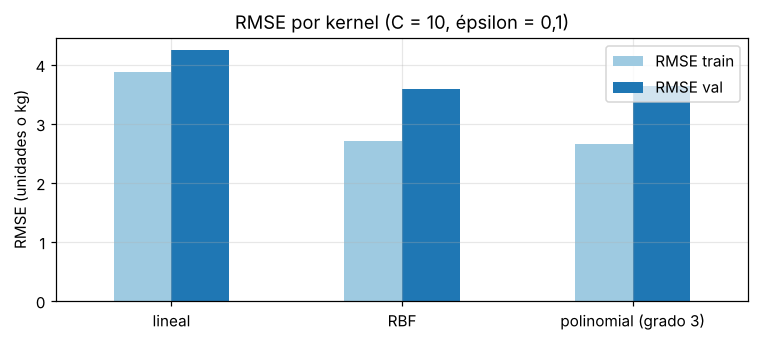

In [4]:
kernels = {"lineal": SVR(kernel="linear", C=10),
           "RBF": SVR(kernel="rbf", C=10),
           "polinomial (grado 3)": SVR(kernel="poly", degree=3, C=10)}
filas = []
for nombre, svr in kernels.items():
    modelo = make_pipeline(StandardScaler(), svr).fit(X_tr, y_tr)
    filas.append({"kernel": nombre,
                  "RMSE train": rmse(y_tr, modelo.predict(X_tr)),
                  "RMSE val": rmse(y_va, modelo.predict(X_va))})
res_kernel = pd.DataFrame(filas).set_index("kernel").round(2)
display(res_kernel)

res_kernel.plot(kind="bar", figsize=(7, 3.2), color=["#9ecae1", "#1f77b4"], rot=0)
plt.title("RMSE por kernel (C = 10, épsilon = 0,1)"); plt.ylabel("RMSE (unidades o kg)"); plt.xlabel("")
plt.tight_layout(); plt.savefig(FIG / "01_kernels.png", dpi=200); plt.show()

**Resultado:** RBF (3,58) y polinomial (3,63) superan al lineal (4,24) en validación, porque la demanda no depende de forma lineal del calendario y los rezagos. Se sigue con **RBF**, que además tiene menos diferencia entre train y validación que el polinomial.

<div id="regularizacion-c" style="color:#37475a; background-color:#fff; border-bottom:3px solid #42A5F5; width:100%; margin-top:24px; margin-bottom:15px; padding-bottom:2px;"><h3 style="color:inherit;">1.4 Efecto de C (regularización)</h3></div>

C es la penalización del error de entrenamiento: con C pequeño el modelo es rígido (subajuste) y con C grande se pega a train (sobreajuste).

,C,train,val
0,0.1,6.80,8.02
1,0.3,5.23,6.20
2,1.0,4.02,4.95
3,3.0,3.18,4.02
4,10.0,2.71,3.58
5,30.0,2.49,3.60
6,100.0,2.31,3.74
7,300.0,2.17,4.03
8,1000.0,1.98,4.45


Mejor C según validación: 10.0


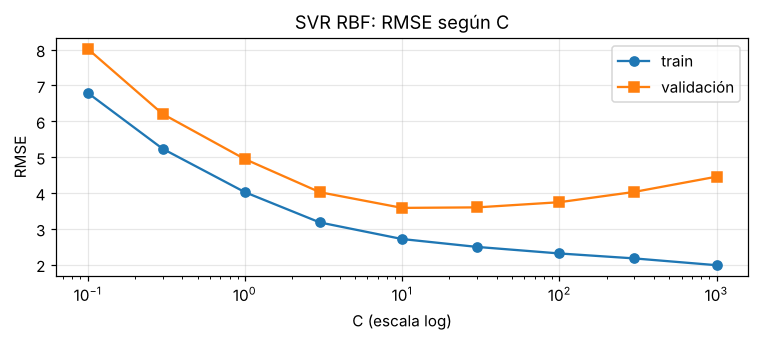

In [5]:
valores_C = [0.1, 0.3, 1, 3, 10, 30, 100, 300, 1000]
filas = []
for C in valores_C:
    modelo = make_pipeline(StandardScaler(), SVR(kernel="rbf", C=C)).fit(X_tr, y_tr)
    filas.append({"C": C, "train": rmse(y_tr, modelo.predict(X_tr)), "val": rmse(y_va, modelo.predict(X_va))})
curva_C = pd.DataFrame(filas)
display(curva_C.round(2))
MEJOR_C = curva_C.loc[curva_C["val"].idxmin(), "C"]
print("Mejor C según validación:", MEJOR_C)

plt.figure(figsize=(7, 3.2))
plt.semilogx(curva_C["C"], curva_C["train"], "o-", label="train")
plt.semilogx(curva_C["C"], curva_C["val"], "s-", label="validación")
plt.title("SVR RBF: RMSE según C"); plt.xlabel("C (escala log)"); plt.ylabel("RMSE"); plt.legend()
plt.tight_layout(); plt.savefig(FIG / "02_curva_C.png", dpi=200); plt.show()

**Resultado:** con C = 0,1 el modelo subajusta (RMSE val 8,02). El mínimo de validación está en **C = 10** (3,58). Desde ahí el error de train sigue bajando (hasta 1,98) pero el de validación sube (4,45 con C = 1000): eso es **sobreajuste**.

<div id="efecto-epsilon" style="color:#37475a; background-color:#fff; border-bottom:3px solid #42A5F5; width:100%; margin-top:24px; margin-bottom:15px; padding-bottom:2px;"><h3 style="color:inherit;">1.5 Efecto de épsilon</h3></div>

Épsilon es el ancho del "tubo": los errores menores a épsilon no se penalizan. Un tubo más ancho deja menos vectores de soporte y un modelo más simple.

,epsilon,RMSE val,% vectores de soporte
0,0.1,3.58,95.87
1,0.5,3.60,80.54
2,1.0,3.61,65.34
3,2.0,3.67,41.74
4,4.0,4.10,18.59
5,8.0,5.48,5.77


Mejor épsilon según validación: 0.1


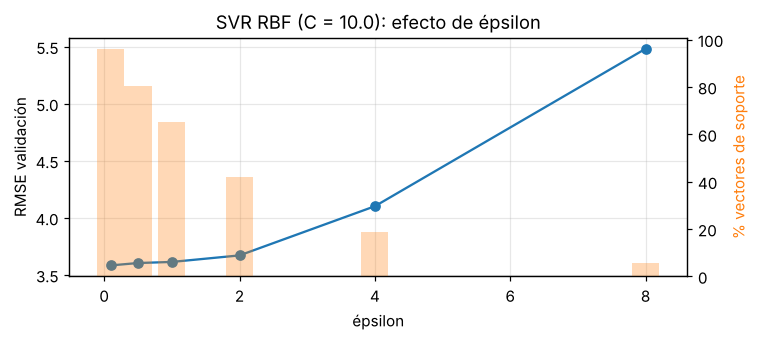

In [6]:
filas = []
for eps in [0.1, 0.5, 1, 2, 4, 8]:
    modelo = make_pipeline(StandardScaler(), SVR(kernel="rbf", C=MEJOR_C, epsilon=eps)).fit(X_tr, y_tr)
    filas.append({"epsilon": eps, "RMSE val": rmse(y_va, modelo.predict(X_va)),
                  "% vectores de soporte": 100 * len(modelo[-1].support_) / len(X_tr)})
curva_eps = pd.DataFrame(filas)
display(curva_eps.round(2))
MEJOR_EPS = curva_eps.loc[curva_eps["RMSE val"].idxmin(), "epsilon"]
print("Mejor épsilon según validación:", MEJOR_EPS)

fig, ax1 = plt.subplots(figsize=(7, 3.2))
ax1.plot(curva_eps["epsilon"], curva_eps["RMSE val"], "o-", color="#1f77b4")
ax1.set(xlabel="épsilon", ylabel="RMSE validación", title=f"SVR RBF (C = {MEJOR_C}): efecto de épsilon")
ax2 = ax1.twinx()
ax2.bar(curva_eps["epsilon"], curva_eps["% vectores de soporte"], width=0.4, alpha=0.3, color="#ff7f0e")
ax2.set_ylabel("% vectores de soporte", color="#ff7f0e"); ax2.grid(False)
plt.tight_layout(); plt.savefig(FIG / "03_epsilon.png", dpi=200); plt.show()

**Resultado:** el mejor épsilon es **0,1** (RMSE val 3,58), aunque usa el 96 % de las filas como vectores de soporte. Con épsilon = 2 el error casi no cambia (3,67) y solo usa el 42 %: un modelo más liviano por muy poco error extra.

<div id="evaluacion-prueba" style="color:#37475a; background-color:#fff; border-bottom:3px solid #42A5F5; width:100%; margin-top:24px; margin-bottom:15px; padding-bottom:2px;"><h3 style="color:inherit;">1.6 Evaluación en prueba</h3></div>

Se entrena el mejor SVR (elegido con validación) con train + validación y se mide en septiembre. Se compara con dos líneas base y con la LSTM de la Práctica 1.

In [7]:
final = make_pipeline(StandardScaler(), SVR(kernel="rbf", C=MEJOR_C, epsilon=MEJOR_EPS))
final.fit(pd.concat([X_tr, X_va]), pd.concat([y_tr, y_va]))
pred = np.clip(final.predict(X_te), 0, None)

comparacion = pd.DataFrame([
    {"modelo": "Base: venta de ayer", "RMSE": rmse(y_te, X_te["venta_ayer"]), "MAE": mean_absolute_error(y_te, X_te["venta_ayer"])},
    {"modelo": "Base: mismo día de la semana anterior", "RMSE": rmse(y_te, X_te["venta_hace_7"]), "MAE": mean_absolute_error(y_te, X_te["venta_hace_7"])},
    {"modelo": "LSTM (Práctica 1)", "RMSE": 4.40, "MAE": 3.10},
    {"modelo": f"SVR RBF (C={MEJOR_C}, ε={MEJOR_EPS})", "RMSE": rmse(y_te, pred), "MAE": mean_absolute_error(y_te, pred)},
]).set_index("modelo").round(2)
display(comparacion)

stock_real = datos.loc[te, "stock_cierre"]
stock_pred = (datos.loc[te, "stock_en_momento"] - pred).clip(lower=0)
print(f"RMSE del stock al cierre calculado con la SVR: {rmse(stock_real, stock_pred):.2f}")

,RMSE,MAE
modelo,,
Base: venta de ayer,6.47,4.51
Base: mismo día de la semana anterior,4.39,3.29
LSTM (Práctica 1),4.40,3.10
"SVR RBF (C=10.0, ε=0.1)",3.21,2.29


RMSE del stock al cierre calculado con la SVR: 3.21


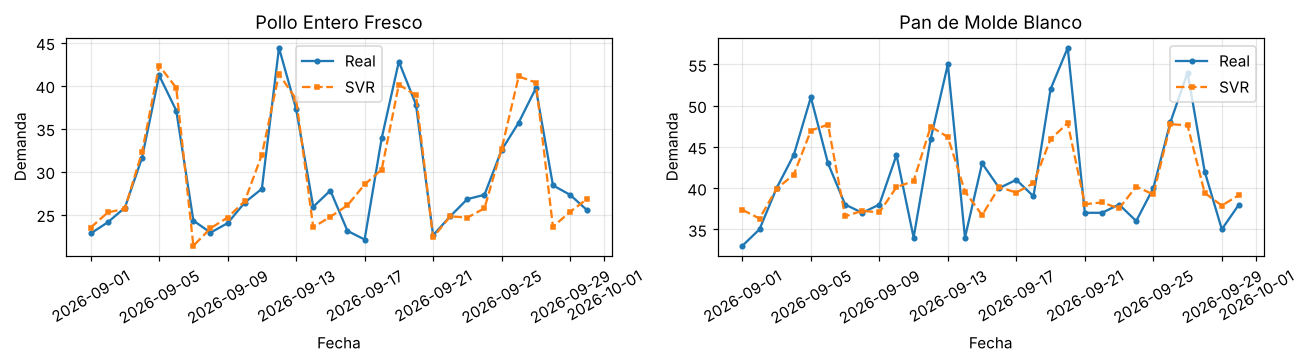

In [8]:
prueba = datos.loc[te, ["product_id", "nombre", "fecha_venta", "cantidad_vendida"]].assign(pred=pred)
fig, ejes = plt.subplots(1, 2, figsize=(12, 3.4))
for ax, cod in zip(ejes, ["114674", "103665"]):
    g = prueba[prueba["product_id"] == cod]
    ax.plot(g["fecha_venta"], g["cantidad_vendida"], "o-", ms=3, label="Real")
    ax.plot(g["fecha_venta"], g["pred"], "s--", ms=3, label="SVR")
    ax.set(title=g["nombre"].iloc[0], xlabel="Fecha", ylabel="Demanda"); ax.legend()
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig(FIG / "04_prediccion_vs_real.png", dpi=200); plt.show()

<div id="parte2" style="color:#37475a; background-color:#fff; border-bottom:7px solid orange; width:100%; margin-top:24px; margin-bottom:15px; padding-bottom:2px;"><h2 style="color:inherit;">Parte 2: Optimización con MLflow</h2></div>

Usamos la misma variable objetivo de la Parte 1: la demanda (`cantidad_vendida`). Probamos GridSearch y RandomSearch con kernel, C, gamma y épsilon. En el kernel lineal dejamos fuera gamma porque ese parámetro no interviene en su cálculo.

<div id="preparacion-parte2" style="color:#37475a; background-color:#fff; border-bottom:3px solid #42A5F5; width:100%; margin-top:24px; margin-bottom:15px; padding-bottom:2px;"><h3 style="color:inherit;">2.1 Preparación y validación temporal</h3></div>

Trabajamos con `X_tr`, `y_tr`, `X_va` e `y_va`. El entrenamiento incluye las fechas anteriores al 2 de agosto y la validación va del 2 al 31 de agosto de 2026. Con `PredefinedSplit` mantenemos esa separación y ajustamos el escalador dentro del pipeline, solo con los datos de entrenamiento. Reservamos septiembre para la prueba final.

GridSearch recorre las 42 combinaciones del espacio definido. RandomSearch toma 20 sin reemplazo, con semilla 42. Como cada método evalúa una cantidad distinta de candidatos, comparamos el error junto con el tiempo que necesita. RandomSearch no garantiza un mejor resultado.

Antes de ejecutar el cuaderno, instalamos las dependencias con `python -m pip install -r requirements.txt`. Los experimentos y sus artefactos quedan en una base SQLite y en archivos locales de MLflow. No hacen falta cuentas ni servicios externos.


In [9]:
import json
import os
from time import perf_counter
os.environ["MLFLOW_DISABLE_TELEMETRY"] = "true"
import mlflow
import mlflow.sklearn
from mlflow import MlflowClient
from mlflow.models import infer_signature
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, PredefinedSplit

TRACKING_URI = "sqlite:///" + (Path.cwd() / "mlflow.db").as_posix()
EXPERIMENTO = "practica2_svr"
MODELO_REGISTRADO = "svr_demanda"
mlflow.set_tracking_uri(TRACKING_URI)
mlflow.set_registry_uri(TRACKING_URI)
cliente = MlflowClient()
experimento = cliente.get_experiment_by_name(EXPERIMENTO)
if experimento is None:
    experimento_id = cliente.create_experiment(
        EXPERIMENTO, artifact_location=(Path.cwd() / "mlartifacts").as_uri())
else:
    experimento_id = experimento.experiment_id
mlflow.set_experiment(EXPERIMENTO)

X_busqueda = pd.concat([X_tr, X_va])
y_busqueda = pd.concat([y_tr, y_va])
division = PredefinedSplit(np.r_[np.full(len(X_tr), -1), np.zeros(len(X_va))].astype(int))
espacio = [
    {"svr__kernel": ["linear"], "svr__C": [1, 10, 100], "svr__epsilon": [0.1, 1]},
    {"svr__kernel": ["rbf", "poly"], "svr__C": [1, 10, 100],
     "svr__gamma": ["scale", 0.01, 0.1], "svr__epsilon": [0.1, 1]},
]
opciones = dict(estimator=make_pipeline(StandardScaler(), SVR()), cv=division,
                scoring="neg_root_mean_squared_error", return_train_score=True,
                refit=False, n_jobs=1, error_score="raise")
busquedas = {
    "GridSearch": GridSearchCV(param_grid=espacio, **opciones),
    "RandomSearch": RandomizedSearchCV(param_distributions=espacio, n_iter=20,
                                        random_state=42, **opciones),
}

2026/11/08 08:25:23 INFO mlflow.agent.hint: Load the `mlflow-trace-instrumentation` skill at C:\Users\kenny\OneDrive\Documents\icc-aa-practica2\icc-aa-practica2\.venv\Lib\site-packages\mlflow\assistant\skills\mlflow-trace-instrumentation\SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


2026/11/08 08:25:25 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/11/08 08:25:25 INFO mlflow.store.db.utils: Updating database tables


<div id="experimentos-mlflow" style="color:#37475a; background-color:#fff; border-bottom:3px solid #42A5F5; width:100%; margin-top:24px; margin-bottom:15px; padding-bottom:2px;"><h3 style="color:inherit;">2.2 Experimentos y registro de cada combinación</h3></div>

En MLflow guardamos una ejecución principal por búsqueda y una ejecución hija por candidato. Cada candidato conserva sus parámetros, los RMSE de entrenamiento y validación, el tiempo de ajuste y una figura con ambos errores.

Tomamos los RMSE de `cv_results_` y cambiamos el signo del criterio de scikit-learn. Estos valores corresponden a modelos que se entrenaron sin los datos de agosto. Para medir la duración, cronometramos únicamente `fit`; la creación de figuras y el registro en MLflow quedan fuera de ese tiempo. Usamos un solo proceso para repetir la medición en las mismas condiciones y evitar saturar el equipo.


In [10]:
filas_experimentos, filas_resumen, runs_busquedas = [], [], {}
for nombre, busqueda in busquedas.items():
    with mlflow.start_run(run_name=nombre) as ejecucion:
        runs_busquedas[nombre] = ejecucion.info.run_id
        mlflow.set_tags({"parte": "2", "busqueda": nombre})
        inicio = perf_counter()
        busqueda.fit(X_busqueda, y_busqueda)
        duracion = perf_counter() - inicio
        cv = busqueda.cv_results_
        for i, parametros_svr in enumerate(cv["params"]):
            parametros = {k.removeprefix("svr__"): v for k, v in parametros_svr.items()}
            parametros.setdefault("gamma", "no_aplica")
            error_train = float(-cv["mean_train_score"][i])
            error_val = float(-cv["mean_test_score"][i])
            with mlflow.start_run(run_name=f"{nombre}_{i + 1:02d}", nested=True) as candidato:
                mlflow.log_params(parametros)
                mlflow.log_metrics({"rmse_train": error_train, "rmse_val": error_val,
                                    "tiempo_fit_s": float(cv["mean_fit_time"][i])})
                fig, ax = plt.subplots(figsize=(4, 2.8))
                ax.bar(["Train", "Validación"], [error_train, error_val], color=["#9ecae1", "#1f77b4"])
                ax.set(title=f"{nombre}: candidato {i + 1}", ylabel="RMSE de demanda")
                fig.tight_layout()
                mlflow.log_figure(fig, "rmse.png")
                plt.close(fig)
                filas_experimentos.append({"busqueda": nombre, "candidato": i + 1,
                    **parametros, "rmse_train": error_train, "rmse_val": error_val,
                    "tiempo_fit_s": float(cv["mean_fit_time"][i]), "run_id": candidato.info.run_id})
        mejor = busqueda.best_index_
        mlflow.log_metrics({"rmse_train": float(-cv["mean_train_score"][mejor]),
                            "rmse_val": float(-busqueda.best_score_), "tiempo_s": duracion,
                            "candidatos": len(cv["params"])})
        filas_resumen.append({"busqueda": nombre, "candidatos": len(cv["params"]),
            "rmse_train": float(-cv["mean_train_score"][mejor]),
            "rmse_val": float(-busqueda.best_score_), "tiempo_s": duracion})
        print(f"{nombre}: {len(cv['params'])} candidatos; RMSE val = {-busqueda.best_score_:.3f}; {duracion:.2f} s")
resultados = pd.DataFrame(filas_experimentos)
resumen_busquedas = pd.DataFrame(filas_resumen).set_index("busqueda")
display(resultados.sort_values("rmse_val").head(10).round(4))

GridSearch: 42 candidatos; RMSE val = 3.290; 128.21 s


RandomSearch: 20 candidatos; RMSE val = 3.506; 57.09 s


,busqueda,candidato,C,epsilon,kernel,gamma,rmse_train,rmse_val,tiempo_fit_s,run_id
38,GridSearch,39,100,1.0,rbf,0.01,2.7862,3.2897,0.4363,dcf873d71b284ea3a69c56d7746ecbcb
32,GridSearch,33,100,0.1,rbf,0.01,2.7980,3.3048,0.6564,cd0fd68b82744a758994ba6ce6a2872e
20,GridSearch,21,10,0.1,rbf,0.01,3.1226,3.4722,0.4182,8e6cbda6e43447eba128a674a05ace93
26,GridSearch,27,10,1.0,rbf,0.01,3.1365,3.5065,0.3036,50d19aafe3b544ad841eb202ea5406a2
45,RandomSearch,4,10,1.0,rbf,0.01,3.1365,3.5065,0.3641,4fe8e98d84e140cbb187f63793b9186f
42,RandomSearch,1,10,1.0,poly,scale,2.6441,3.5641,0.5326,79235d3d255e41ec933c9d717641924b
25,GridSearch,26,10,1.0,poly,scale,2.6441,3.5641,0.4098,2f66e1c6f3324b35a8c989b1723fce47
17,GridSearch,18,1,1.0,poly,0.1,2.6341,3.5675,0.3690,7e7964160bf74127a87cfdfbecb0d99c
54,RandomSearch,13,1,1.0,poly,0.1,2.6341,3.5675,0.4520,b09a205d61b64247926c310961bb008b
18,GridSearch,19,10,0.1,rbf,scale,2.7138,3.5829,0.4378,4f8837f61fba4d95b3dba27867128ed9


<div id="grid-frente-random" style="color:#37475a; background-color:#fff; border-bottom:3px solid #42A5F5; width:100%; margin-top:24px; margin-bottom:15px; padding-bottom:2px;"><h3 style="color:inherit;">2.3 GridSearch frente a RandomSearch</h3></div>

Comparamos el mejor RMSE de agosto de cada búsqueda y el tiempo total que necesitó para probar sus candidatos. Guardamos ambos resultados en una figura y exportamos los datos a CSV, de modo que también puedan revisarse sin abrir MLflow.


,candidatos,rmse_train,rmse_val,tiempo_s
busqueda,,,,
GridSearch,42,2.7862,3.2897,128.2055
RandomSearch,20,3.1365,3.5065,57.0887


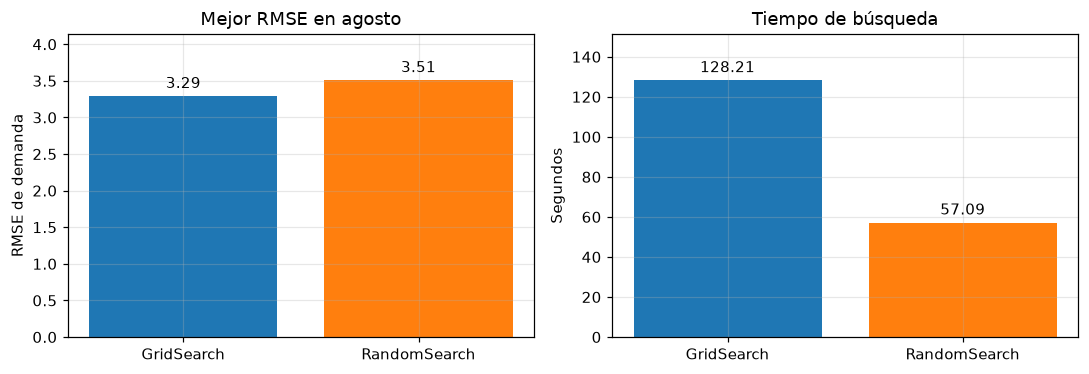

In [11]:
SALIDA = Path("resultados")
SALIDA.mkdir(exist_ok=True)
resultados.to_csv(SALIDA / "parte2_experimentos.csv", index=False)
resumen_busquedas.to_csv(SALIDA / "parte2_comparacion.csv")
display(resumen_busquedas.round(4))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, columna, titulo, unidad in zip(axes, ["rmse_val", "tiempo_s"],
        ["Mejor RMSE en agosto", "Tiempo de búsqueda"], ["RMSE de demanda", "Segundos"]):
    barras = ax.bar(resumen_busquedas.index, resumen_busquedas[columna], color=["#1f77b4", "#ff7f0e"])
    ax.set(title=titulo, ylabel=unidad)
    ax.bar_label(barras, fmt="%.2f", padding=3)
    ax.margins(y=0.18)
fig.tight_layout()
fig.savefig(FIG / "05_grid_vs_random.png", dpi=200)
for run_id in runs_busquedas.values():
    with mlflow.start_run(run_id=run_id):
        mlflow.log_figure(fig, "grid_vs_random.png")
        mlflow.log_artifact(str(SALIDA / "parte2_experimentos.csv"))
        mlflow.log_artifact(str(SALIDA / "parte2_comparacion.csv"))
plt.show()

<div id="registro-modelo" style="color:#37475a; background-color:#fff; border-bottom:3px solid #42A5F5; width:100%; margin-top:24px; margin-bottom:15px; padding-bottom:2px;"><h3 style="color:inherit;">2.4 Registro del mejor modelo</h3></div>

Elegimos la configuración con el menor RMSE de agosto. Si hay empate, tomamos la búsqueda que terminó en menos tiempo. Con los parámetros ya elegidos, entrenamos de nuevo el pipeline completo con train + agosto y lo evaluamos una vez en septiembre. El resultado de septiembre queda como evaluación final y no cambia la selección.

Guardamos StandardScaler + SVR junto con el esquema de entrada. La primera ejecución crea la versión 1 de `svr_demanda`; al volver a ejecutar se crean otras versiones y se conservan las anteriores. En `resultados/parte2_modelo.json` dejamos el nombre, la versión, la URI y las columnas que necesitará el compañero para la Parte 3.


In [12]:
ganador = resumen_busquedas.sort_values(["rmse_val", "tiempo_s"]).index[0]
seleccionada = busquedas[ganador]
mejor_modelo = clone(seleccionada.estimator).set_params(**seleccionada.best_params_)
mejor_modelo.fit(X_busqueda, y_busqueda)
pred_parte2 = mejor_modelo.predict(X_te)
rmse_test_parte2 = float(rmse(y_te, pred_parte2))
with mlflow.start_run(run_name="mejor_modelo") as ejecucion_final:
    mlflow.set_tags({"parte": "2", "busqueda_origen": ganador})
    mlflow.log_params({k.removeprefix("svr__"): v for k, v in seleccionada.best_params_.items()})
    mlflow.log_metrics({"rmse_val_seleccion": float(-seleccionada.best_score_),
                        "rmse_test": rmse_test_parte2,
                        "rmse_train_final": float(rmse(y_busqueda, mejor_modelo.predict(X_busqueda)))})
    firma = infer_signature(X_tr, mejor_modelo.predict(X_tr))
    modelo_guardado = mlflow.sklearn.log_model(mejor_modelo, name="modelo",
                                               signature=firma, input_example=X_tr.head(2))
    version_registrada = mlflow.register_model(modelo_guardado.model_uri, MODELO_REGISTRADO)
    modelo_uri = f"models:/{MODELO_REGISTRADO}/{version_registrada.version}"
    entrega_parte2 = {"nombre": MODELO_REGISTRADO, "version": version_registrada.version,
        "modelo_uri": modelo_uri, "tracking_uri": TRACKING_URI,
        "run_id": ejecucion_final.info.run_id, "busqueda": ganador,
        "parametros": seleccionada.best_params_, "columnas": list(X_tr.columns),
        "objetivo": "cantidad_vendida", "rmse_val": float(-seleccionada.best_score_),
        "rmse_test": rmse_test_parte2}
    (SALIDA / "parte2_modelo.json").write_text(
        json.dumps(entrega_parte2, ensure_ascii=False, indent=2), encoding="utf-8")
    mlflow.log_artifact(str(SALIDA / "parte2_modelo.json"))
print(f"Modelo registrado: {modelo_uri}")
print(f"Búsqueda elegida: {ganador}; RMSE val: {-seleccionada.best_score_:.3f}; RMSE test: {rmse_test_parte2:.3f}")

C:\Users\kenny\OneDrive\Documents\icc-aa-practica2\icc-aa-practica2\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


Modelo registrado: models:/svr_demanda/1
Búsqueda elegida: GridSearch; RMSE val: 3.290; RMSE test: 3.046


Successfully registered model 'svr_demanda'.
Created version '1' of model 'svr_demanda'.


<div id="resultados-parte2" style="color:#37475a; background-color:#fff; border-bottom:3px solid #42A5F5; width:100%; margin-top:24px; margin-bottom:15px; padding-bottom:2px;"><h3 style="color:inherit;">2.5 Resultados y entrega para la Parte 3</h3></div>

Las conclusiones usan los resultados de esta ejecución y el modelo registrado queda disponible para la Parte 3. Los tiempos dependen del equipo; una búsqueda que terminó antes aquí puede tardar más en otra ejecución.


In [13]:
from IPython.display import Markdown
rapida = resumen_busquedas["tiempo_s"].idxmin()
display(Markdown(
    f"**Conclusiones de la Parte 2:** {ganador} proporcionó el modelo seleccionado, con "
    f"RMSE de validación **{-seleccionada.best_score_:.3f}** y parámetros "
    f"`{seleccionada.best_params_}`. La búsqueda más rápida fue **{rapida}**, con "
    f"**{resumen_busquedas.loc[rapida, 'tiempo_s']:.2f} s**. Después del ajuste con train + agosto, "
    f"el modelo obtuvo RMSE **{rmse_test_parte2:.3f}** en septiembre. "
    f"Quedó disponible como **`{modelo_uri}`** para que la Parte 3 lo cargue sin volver a entrenar."
))
print("Para abrir MLflow, ejecutar desde la carpeta del proyecto:")
print("python -m mlflow ui --backend-store-uri sqlite:///mlflow.db --host 127.0.0.1 --port 5000")

**Conclusiones de la Parte 2:** GridSearch proporcionó el modelo seleccionado, con RMSE de validación **3.290** y parámetros `{'svr__C': 100, 'svr__epsilon': 1, 'svr__gamma': 0.01, 'svr__kernel': 'rbf'}`. La búsqueda más rápida fue **RandomSearch**, con **57.09 s**. Después del ajuste con train + agosto, el modelo obtuvo RMSE **3.046** en septiembre. Quedó disponible como **`models:/svr_demanda/1`** para que la Parte 3 lo cargue sin volver a entrenar.

Para abrir MLflow, ejecutar desde la carpeta del proyecto:
python -m mlflow ui --backend-store-uri sqlite:///mlflow.db --host 127.0.0.1 --port 5000


<div id="conclusiones-parte1" style="color:#37475a; background-color:#fff; border-bottom:7px solid orange; width:100%; margin-top:24px; margin-bottom:15px; padding-bottom:2px;"><h2 style="color:inherit;">Conclusiones de la Parte 1</h2></div>

1. **Kernel:** el RBF es el mejor para esta demanda (RMSE val 3,58 frente a 4,24 del lineal), porque la relación con el calendario y los rezagos no es lineal.
2. **C controla el sobreajuste:** C = 10 da el menor error de validación. Con C = 1000 el error de train baja a 1,98 pero el de validación sube a 4,45.
3. **Épsilon:** 0,1 da el menor error, pero épsilon = 2 deja menos de la mitad de vectores de soporte con casi el mismo RMSE (3,67).
4. **Prueba (septiembre 2026):** la SVR RBF logra **RMSE 3,21 y MAE 2,29**, mejor que la LSTM de la Práctica 1 (4,40 / 3,10) y que la base del mismo día de la semana anterior (4,39 / 3,29). El stock al cierre calculado con esta demanda tiene RMSE 3,21.
5. **Por qué funciona:** con solo 3.580 filas, la SVR aprovecha bien las variables de calendario y los rezagos, sin necesitar tantos datos como la red recurrente.

**Parte 3 (a cargo del compañero):** función de predicción que cargue una versión registrada, dos casos nuevos y explicación con SHAP. Esta parte no se implementa aquí.

<div id="referencias" style="color:#37475a; background-color:#fff; border-bottom:7px solid orange; width:100%; margin-top:24px; margin-bottom:15px; padding-bottom:2px;"><h2 style="color:inherit;">Referencias</h2></div>

- Bishop, C. M. (2006). *Pattern recognition and machine learning*. Springer.
- Schölkopf, B., & Smola, A. J. (2002). *Learning with kernels: Support vector machines, regularization, optimization, and beyond*. MIT Press.
- Raschka, S., & Mirjalili, V. (2017). *Python machine learning* (2.ª ed.). Packt Publishing.
- Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.